In [1]:
import os
from smard import fetch_prices

prices = fetch_prices(weeks=52)
os.makedirs("data", exist_ok=True)
prices.to_csv("data/prices_hourly.csv")

print(prices.shape)
print(prices.index.min(), "→", prices.index.max())
print("Negative-price hours:", (prices["price_eur_mwh"] < 0).sum())
prices.describe()

(8664, 1)
2025-10-20 00:00:00+02:00 → 2026-10-15 23:00:00+02:00
Negative-price hours: 471


,price_eur_mwh
count,8664.000000
mean,106.781982
std,62.983753
min,-499.000000
25%,79.507500
50%,106.265000
75%,139.945000
max,697.310000


Matplotlib is building the font cache; this may take a moment.


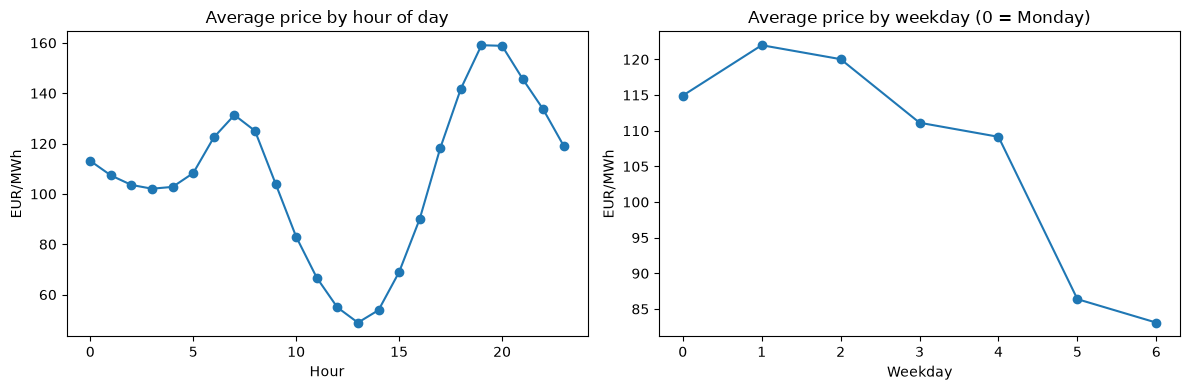

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prices.groupby(prices.index.hour)["price_eur_mwh"].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Average price by hour of day", xlabel="Hour", ylabel="EUR/MWh")
prices.groupby(prices.index.dayofweek)["price_eur_mwh"].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="Average price by weekday (0 = Monday)", xlabel="Weekday", ylabel="EUR/MWh")
plt.tight_layout()
plt.show()

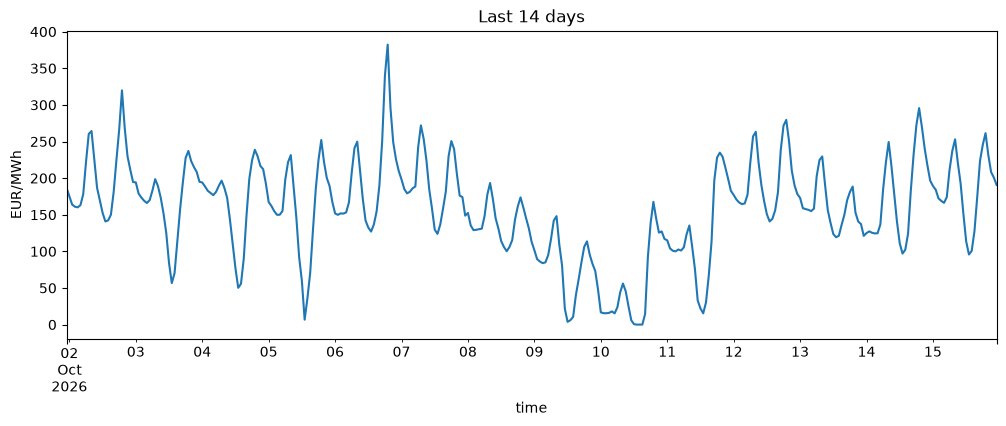

In [5]:
import pandas as pd

cutoff = prices.index.max() - pd.Timedelta(days=14)
prices[prices.index >= cutoff].plot(figsize=(12, 4), title="Last 14 days", ylabel="EUR/MWh", legend=False)
plt.show()